# Data pipeline notebook

First few blocks are gonna be for playing around and analyzing data

Imports

In [10]:
import json, time
from pathlib import Path

import numpy as np
import stim                       # stabilizer-circuit simulator: makes the data
import pymatching                 # minimum-weight perfect matching: the baseline decoder
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import SVG, display

print("stim", stim.__version__, "| pymatching", pymatching.__version__, "| numpy", np.__version__)

stim 1.16.0 | pymatching 2.4.0 | numpy 2.5.3


Configurations

In [11]:
DISTANCE = 3
ROUNDS = 3
P = 0.005     # physical error rate applied to every noise channel
SEED = 1234   # fixed seed so the sampled outputs are reproducible

Building Circuit

In [12]:
circuit = stim.Circuit.generated(
    "surface_code:rotated_memory_z",
    distance=DISTANCE,
    rounds=ROUNDS,
    after_clifford_depolarization=P,      # DEPOLARIZE1/2 after every H / CX
    before_round_data_depolarization=P,   # idle noise on data qubits each round
    before_measure_flip_probability=P,    # measurement flips
    after_reset_flip_probability=P,       # reset flips
)

# In Stim's layout, data qubits sit at odd (x, y) coordinates and measure qubits at even ones.
coords = circuit.get_final_qubit_coordinates()
data_qubits = sorted(q for q, (x, y) in coords.items() if x % 2 == 1)
measure_qubits = sorted(q for q, (x, y) in coords.items() if x % 2 == 0)
N_DATA, N_ANC = len(data_qubits), len(measure_qubits)

print(f"data qubits     ({N_DATA}): {data_qubits}")
print(f"measure qubits  ({N_ANC}): {measure_qubits}")
print(f"measurements / shot : {circuit.num_measurements}  (= {N_ANC} measure qubits x {ROUNDS} rounds + {N_DATA} final data)")
print(f"detectors           : {circuit.num_detectors}")
print(f"logical observables : {circuit.num_observables}")

data qubits     (9): [1, 3, 5, 8, 10, 12, 15, 17, 19]
measure qubits  (8): [2, 9, 11, 13, 14, 16, 18, 25]
measurements / shot : 33  (= 8 measure qubits x 3 rounds + 9 final data)
detectors           : 24
logical observables : 1


Print Circuit Design

In [13]:
print(circuit)

QUBIT_COORDS(1, 1) 1
QUBIT_COORDS(2, 0) 2
QUBIT_COORDS(3, 1) 3
QUBIT_COORDS(5, 1) 5
QUBIT_COORDS(1, 3) 8
QUBIT_COORDS(2, 2) 9
QUBIT_COORDS(3, 3) 10
QUBIT_COORDS(4, 2) 11
QUBIT_COORDS(5, 3) 12
QUBIT_COORDS(6, 2) 13
QUBIT_COORDS(0, 4) 14
QUBIT_COORDS(1, 5) 15
QUBIT_COORDS(2, 4) 16
QUBIT_COORDS(3, 5) 17
QUBIT_COORDS(4, 4) 18
QUBIT_COORDS(5, 5) 19
QUBIT_COORDS(4, 6) 25
R 1 3 5 8 10 12 15 17 19
X_ERROR(0.005) 1 3 5 8 10 12 15 17 19
R 2 9 11 13 14 16 18 25
X_ERROR(0.005) 2 9 11 13 14 16 18 25
TICK
DEPOLARIZE1(0.005) 1 3 5 8 10 12 15 17 19
H 2 11 16 25
DEPOLARIZE1(0.005) 2 11 16 25
TICK
CX 2 3 16 17 11 12 15 14 10 9 19 18
DEPOLARIZE2(0.005) 2 3 16 17 11 12 15 14 10 9 19 18
TICK
CX 2 1 16 15 11 10 8 14 3 9 12 18
DEPOLARIZE2(0.005) 2 1 16 15 11 10 8 14 3 9 12 18
TICK
CX 16 10 11 5 25 19 8 9 17 18 12 13
DEPOLARIZE2(0.005) 16 10 11 5 25 19 8 9 17 18 12 13
TICK
CX 16 8 11 3 25 17 1 9 10 18 5 13
DEPOLARIZE2(0.005) 16 8 11 3 25 17 1 9 10 18 5 13
TICK
H 2 11 16 25
DEPOLARIZE1(0.005) 2 11 16 25
TICK
X

Time slice betweeen ticks: Reset, Hadamar on X, 4 C-Not, Hadamar, measure, reset

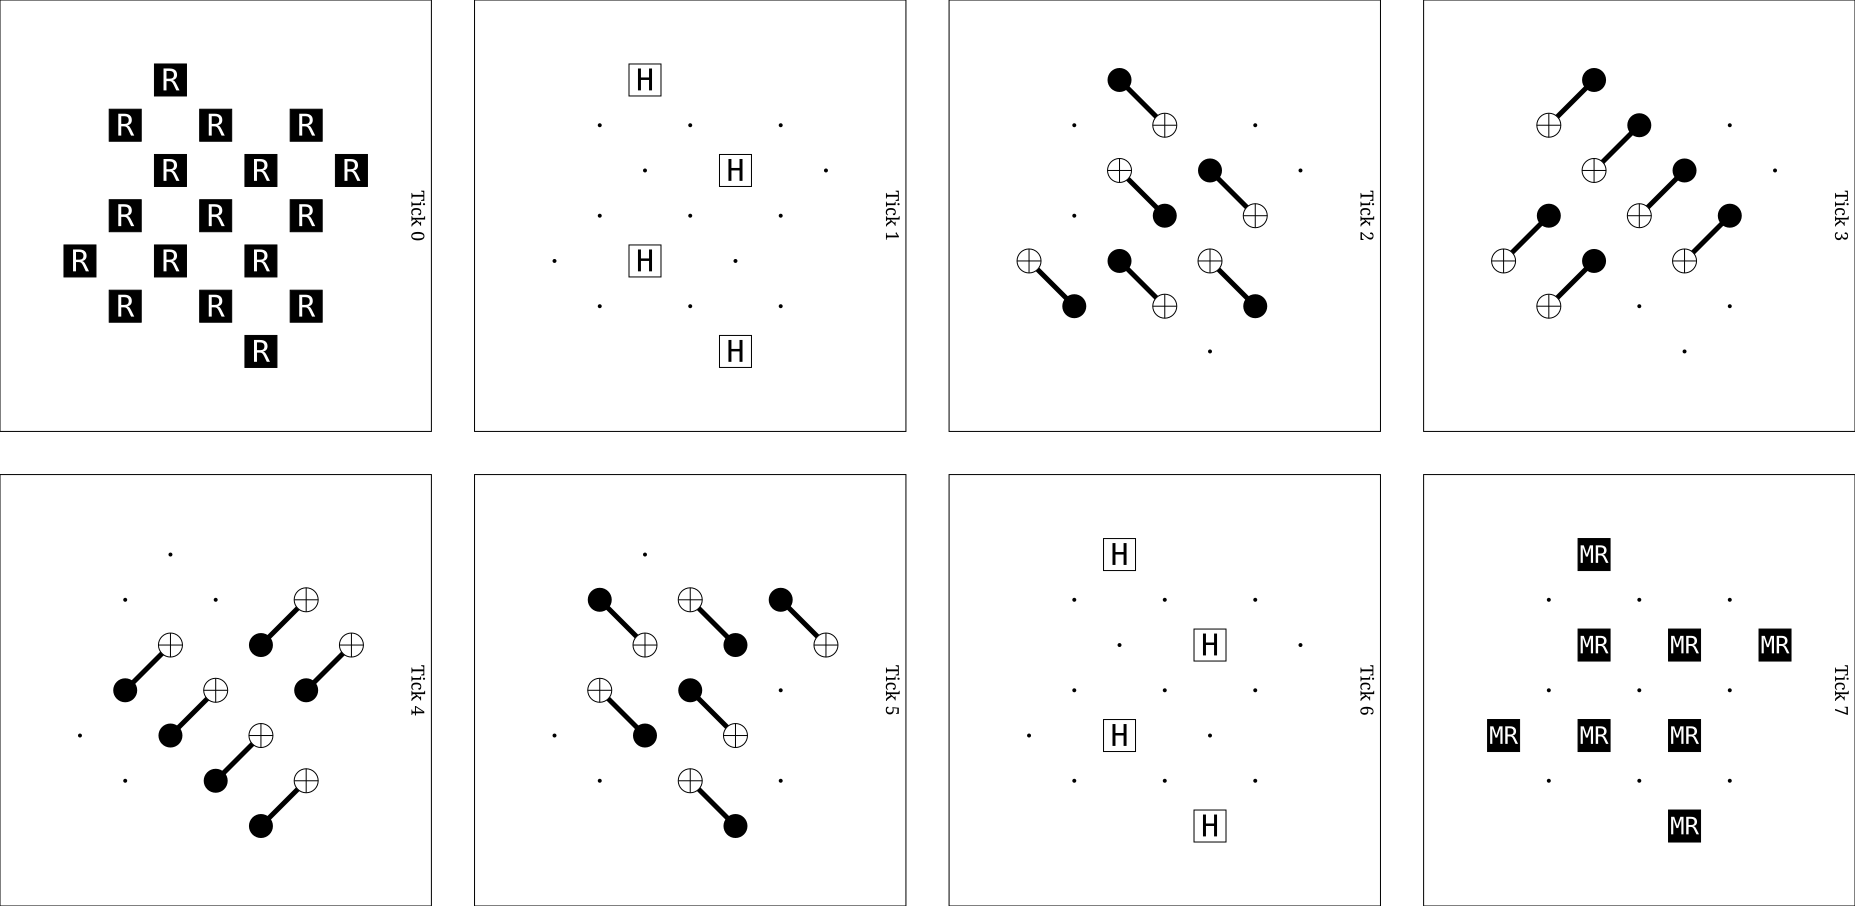

In [14]:
circuit.without_noise().diagram("timeslice-svg", tick = range(0,8), rows=2)

Shots and Rounds Raw measurements. X-bits are random in r0

In [15]:
meas = circuit.compile_sampler(seed=SEED).sample(shots=5).astype(np.uint8)
print("shape:", meas.shape, "\n")

bits = lambda a: "".join(map(str, a))
print(" " * 8 + "   ".join(f"round {r} " for r in range(ROUNDS)) + "   final data")
for s, row in enumerate(meas):
    rounds_str = "   ".join(bits(row[r * N_ANC:(r + 1) * N_ANC]) for r in range(ROUNDS))
    print(f"shot {s}: {rounds_str}   {bits(row[ROUNDS * N_ANC:])}")

shape: (5, 33) 

        round 0    round 1    round 2    final data
shot 0: 10000000   10000000   10000000   011111101
shot 1: 10100000   11100000   00100000   110100011
shot 2: 10000000   10000000   10000000   000000011
shot 3: 10100000   10100000   10100000   000110110
shot 4: 00100100   00100100   00100100   101011011


Detection Events : When a measurement changed

In [16]:
det_sampler = circuit.compile_detector_sampler(seed=SEED)
dets, obs = det_sampler.sample(shots=10, separate_observables=True)
print("detection events:", dets.shape, dets.dtype)
print("observable flips:", obs.shape, obs.dtype, "\n")

det_coords = circuit.get_detector_coordinates()
det_t = np.array([int(det_coords[i][2]) for i in range(circuit.num_detectors)])

print("         " + "   ".join(f"t={t} ({np.sum(det_t == t)})".ljust(max(8, np.sum(det_t == t))) for t in range(det_t.max() + 1)) + "   obs")
for s in range(len(dets)):
    groups = "   ".join(bits(dets[s, det_t == t].astype(np.uint8)).ljust(max(8, np.sum(det_t == t))) for t in range(det_t.max() + 1))
    print(f"shot {s}:  {groups}   {int(obs[s, 0])}")

detection events: (10, 24) bool
observable flips: (10, 1) bool 

         t=0 (4)    t=1 (8)    t=2 (8)    t=3 (4)    obs
shot 0:  0000       00000010   00000010   0000       0
shot 1:  0000       00000000   00000000   0000       0
shot 2:  0000       00000000   00100000   0000       0
shot 3:  0000       00000100   00000100   0000       0
shot 4:  0000       00000000   00000010   0010       0
shot 5:  0000       00000000   00000000   0000       0
shot 6:  0000       00000110   00000111   0010       0
shot 7:  0000       00000010   00000010   0000       0
shot 8:  0000       00000000   00000000   0000       0
shot 9:  0000       00000000   00000010   0010       0


Detector Error Model

In [17]:
dem = circuit.detector_error_model(decompose_errors=True)
print("error mechanisms:", dem.num_errors, "| detectors:", dem.num_detectors, "| observables:", dem.num_observables, "\n")
print("\n".join(str(dem).splitlines()[:20]))
print("...")

error mechanisms: 286 | detectors: 24 | observables: 1 

error(0.0096129529443096) D0
error(0.0096129529443096) D0 D1
error(0.01125854706194612) D0 D8
error(0.0096129529443096) D1 D2
error(0.01191150971274241) D1 D5
error(0.0006680041634191543) D1 D5 ^ D4
error(0.002001336305216213) D1 D8
error(0.0006680041634191543) D1 D8 ^ D4
error(0.0203253599098319) D1 L0
error(0.02000461382778225) D2
error(0.01092240000000015) D2 D3
error(0.002666666666666795) D2 D3 ^ D6
error(0.002998998440543733) D2 D5
error(0.001001671498398811) D2 D5 ^ D6
error(0.0006680041634191543) D2 D5 ^ D6 D9
error(0.0003341137136832484) D2 D5 ^ D9
error(0.0003341137136832484) D2 D5 ^ D9 ^ D6
error(0.0003341137136832484) D2 D8
error(0.0003341137136832484) D2 D8 ^ D6
error(0.0003341137136832484) D2 D8 ^ D9
...


MWPM example

In [18]:
matcher = pymatching.Matching.from_detector_error_model(dem)

N_SHOTS = 100_000
dets, obs = circuit.compile_detector_sampler(seed=SEED).sample(N_SHOTS, separate_observables=True)
pred = matcher.decode_batch(dets)

mwpm_errors = np.sum(np.any(pred != obs, axis=1))
print(f"shots                      : {N_SHOTS:,}")
print(f"no decoding  logical error : {np.mean(obs[:, 0]):.4%}")
print(f"MWPM         logical error : {mwpm_errors / N_SHOTS:.4%}  ({mwpm_errors} failures)")

shots                      : 100,000
no decoding  logical error : 10.2820%
MWPM         logical error : 1.6190%  (1619 failures)


Helper Functions

In [19]:
def make_circuit(distance=DISTANCE, rounds=ROUNDS, p=P, basis="z"):
    # Same settings as "Building Circuit"; basis "z" or "x"
    return stim.Circuit.generated(
        f"surface_code:rotated_memory_{basis}", distance=distance, rounds=rounds,
        after_clifford_depolarization=p, before_round_data_depolarization=p,
        before_measure_flip_probability=p, after_reset_flip_probability=p)

assert str(make_circuit()) == str(circuit)          # identical to the circuit built above

def show_grid(values, mask, names, title=""):
    # Print one [round, stabilizer] grid; "." = no detector exists in that slot
    R = values.shape[0]
    rows = [f"r{r}" for r in range(R - 1)] + ["final"]
    print(title)
    print("        " + "".join(f"{n:>4s}" for n in names))
    for r in range(R):
        cells = "".join(f"{'.' if (mask is not None and not mask[r, s]) else int(values[r, s]):>4}" for s in range(values.shape[1]))
        print(f"{rows[r]:>6s}  {cells}")
    print()

Reorder into [round, stabilizer]

In [20]:
def detector_layout(circ, basis="z"):
    qc = circ.get_final_qubit_coordinates()
    dc = circ.get_detector_coordinates()
    xyt = np.array([dc[k] for k in range(circ.num_detectors)])
    # stabilizer positions = measure qubits (even x), in reading order: top to bottom, then left to right
    slots = sorted({tuple(xy) for q, xy in qc.items() if xy[0] % 2 == 0}, key=lambda xy: (xy[1], xy[0]))
    det_round = xyt[:, 2].astype(int)                         # 0 .. rounds (last row = final data readout)
    det_slot = np.array([slots.index((x, y)) for x, y, _ in xyt])
    # stabilizer type: round-0 detectors belong to checks of the experiment's own basis
    first = {slots[s] for s in det_slot[det_round == 0]}
    own, other = basis.upper(), ("X" if basis == "z" else "Z")
    types = [own if xy in first else other for xy in slots]
    count, names = {"X": 0, "Z": 0}, []
    for t in types:
        count[t] += 1
        names.append(f"{t}{count[t]}")
    return dict(det_round=det_round, det_slot=det_slot, slots=slots, types=types, names=names,
                n_rounds=int(det_round.max()) + 1, n_stab=len(slots))

def to_grid(dets, lay):
    # bool [N, detectors] -> uint8 [N, rounds+1, stabilizers]; slots with no detector stay 0
    grid = np.zeros((len(dets), lay["n_rounds"], lay["n_stab"]), np.uint8)
    grid[:, lay["det_round"], lay["det_slot"]] = dets
    return grid

lay = detector_layout(circuit, "z")
names = lay["names"]
grid = to_grid(dets, lay)
assert (grid[:, lay["det_round"], lay["det_slot"]] == dets).all()   # nothing lost or moved

# example shot used below: a few events, one of them in round 0 at a check Stim lists out of reading order
r0 = dets[:, det_t == 0]
EX = int(np.argmax((dets.sum(axis=1) >= 3) & (r0[:, 0] | r0[:, 3])))

print("flat:", dets.shape, "-> grid:", grid.shape, "  (shots, rounds+1, stabilizers)\n")
print(f"shot {EX} as Stim gives it (detector order per round):")
for t in range(det_t.max() + 1):
    ks = np.flatnonzero(det_t == t)
    print(f"  t={t}: " + " ".join(f"{names[s]:>3s}" for s in lay["det_slot"][ks]))
    print("        " + " ".join(f"{b:>3d}" for b in dets[EX, ks].astype(np.uint8)))
print()
show_grid(grid[EX], None, names, f"shot {EX} as a grid, same column order every round (missing slots still shown as 0 here):")

flat: (100000, 24) -> grid: (100000, 4, 8)   (shots, rounds+1, stabilizers)

shot 26 as Stim gives it (detector order per round):
  t=0:  Z3  Z1  Z4  Z2
          1   0   0   0
  t=1:  X1  Z1  X2  Z2  Z3  X3  Z4  X4
          0   0   0   0   0   1   1   0
  t=2:  X1  Z1  X2  Z2  Z3  X3  Z4  X4
          0   0   0   0   0   0   0   0
  t=3:  Z3  Z1  Z4  Z2
          0   0   0   0

shot 26 as a grid, same column order every round (missing slots still shown as 0 here):
          X1  Z1  X2  Z2  Z3  X3  Z4  X4
    r0     0   0   0   0   1   0   0   0
    r1     0   0   0   0   0   1   1   0
    r2     0   0   0   0   0   0   0   0
 final     0   0   0   0   0   0   0   0



Mask Channel

In [21]:
mask = np.zeros((lay["n_rounds"], lay["n_stab"]), np.uint8)
mask[lay["det_round"], lay["det_slot"]] = 1

show_grid(grid[EX], mask, names, f"shot {EX} events ('.' = no detector):")
show_grid(mask, None, names, "mask:")

shot 26 events ('.' = no detector):
          X1  Z1  X2  Z2  Z3  X3  Z4  X4
    r0     .   0   .   0   1   .   0   .
    r1     0   0   0   0   0   1   1   0
    r2     0   0   0   0   0   0   0   0
 final     .   0   .   0   0   .   0   .

mask:
          X1  Z1  X2  Z2  Z3  X3  Z4  X4
    r0     0   1   0   1   1   0   1   0
    r1     1   1   1   1   1   1   1   1
    r2     1   1   1   1   1   1   1   1
 final     0   1   0   1   1   0   1   0



Final Round Flag

In [22]:
final_flag = np.zeros_like(mask)
final_flag[-1, :] = 1
show_grid(final_flag, None, names, "final-round flag:")

final-round flag:
          X1  Z1  X2  Z2  Z3  X3  Z4  X4
    r0     0   0   0   0   0   0   0   0
    r1     0   0   0   0   0   0   0   0
    r2     0   0   0   0   0   0   0   0
 final     1   1   1   1   1   1   1   1



Convert to float 32

In [23]:
X_float = grid.astype(np.float32)        # inputs
y_float = obs.astype(np.float32)         # labels, their own array
print("inputs:", X_float.shape, X_float.dtype, f"{X_float.nbytes / 1e6:.1f} MB")
print("labels:", y_float.shape, y_float.dtype)

inputs: (100000, 4, 8) float32 12.8 MB
labels: (100000, 1) float32


Split by seed, shuffle shots: Have train, validate, and test sets use different seeds

In [24]:
TRAIN, VAL, TEST = 0, 1, 2

def seed_for(*path):
    # 64-bit Stim seed from (root SEED, role, batch, ...): different paths never collide
    return int(np.random.SeedSequence(SEED, spawn_key=path).generate_state(1, dtype=np.uint64)[0])

train_dets, train_obs = circuit.compile_detector_sampler(seed=seed_for(TRAIN, 0)).sample(50_000, separate_observables=True)
val_dets,   val_obs   = circuit.compile_detector_sampler(seed=seed_for(VAL)).sample(10_000, separate_observables=True)
test_dets,  test_obs  = circuit.compile_detector_sampler(seed=seed_for(TEST)).sample(50_000, separate_observables=True)

perm = np.random.default_rng(seed_for(TRAIN, 999)).permutation(len(train_dets))
train_dets, train_obs = train_dets[perm], train_obs[perm]          # shots move together with their labels

print(f"train {train_dets.shape}  val {val_dets.shape}  test {test_dets.shape}")
test_mwpm = np.mean(matcher.decode_batch(test_dets)[:, 0] != test_obs[:, 0])
print(f"MWPM on the test set (the number to beat): {test_mwpm:.3%} ± {np.sqrt(test_mwpm * (1 - test_mwpm) / len(test_obs)):.3%}")

train (50000, 24)  val (10000, 24)  test (50000, 24)
MWPM on the test set (the number to beat): 1.784% ± 0.059%


Stabilizer Channel

In [25]:
is_x = np.array([t == "X" for t in lay["types"]], np.uint8)
stab_type = np.broadcast_to(is_x, mask.shape)                     # 1 = X check

# check against the circuit: X-type measure qubits are the ones that get Hadamard gates
had = {t.value for inst in circuit.flattened() if inst.name == "H" for t in inst.targets_copy()}
pos_to_q = {tuple(coords[q]): q for q in measure_qubits}
assert ["X" if pos_to_q[xy] in had else "Z" for xy in lay["slots"]] == lay["types"]

show_grid(stab_type, None, names, "type channel (1 = X check):")

type channel (1 = X check):
          X1  Z1  X2  Z2  Z3  X3  Z4  X4
    r0     1   0   1   0   0   1   0   1
    r1     1   0   1   0   0   1   0   1
    r2     1   0   1   0   0   1   0   1
 final     1   0   1   0   0   1   0   1



2d - pixel map (FOR CNN)

In [26]:
D1 = DISTANCE + 1
pix = [(int(y) // 2, int(x) // 2) for x, y in lay["slots"]]       # pixel of each stabilizer
img = np.zeros((len(grid), lay["n_rounds"], D1, D1), np.uint8)
for s, (row, col) in enumerate(pix):
    img[:, :, row, col] = grid[:, :, s]
print("image tensor:", img.shape, "  (shots, rounds+1, d+1, d+1)\n")

name_px = [["  ." for _ in range(D1)] for _ in range(D1)]
for s, (row, col) in enumerate(pix):
    name_px[row][col] = f"{names[s]:>3s}"
print("pixel map:          " + "    ".join(f"r{r}" if r < lay["n_rounds"] - 1 else "final" for r in range(lay["n_rounds"])))
for row in range(D1):
    frames = "   ".join("".join(f"{img[EX, r, row, col]:>2d}" if name_px[row][col] != "  ." else " ." for col in range(D1))
                        for r in range(lay["n_rounds"]))
    print("".join(name_px[row]) + "      " + frames)

image tensor: (100000, 4, 4, 4)   (shots, rounds+1, d+1, d+1)

pixel map:          r0    r1    r2    final
  . X1  .  .       . 0 . .    . 0 . .    . 0 . .    . 0 . .
  . Z1 X2 Z2       . 0 0 0    . 0 0 0    . 0 0 0    . 0 0 0
 Z3 X3 Z4  .       1 0 0 .    0 1 1 .    0 0 0 .    0 0 0 .
  .  . X4  .       . . 0 .    . . 0 .    . . 0 .    . . 0 .


Train on mix of noise

In [27]:
print(f"{'p':>7} {'label = 1':>10} {'MWPM wrong':>11} {'empty shots':>12}   (per 50,000 shots)")
for j, p in enumerate([0.001, 0.0025, 0.005, 0.01]):
    c = make_circuit(p=p)
    d_, o_ = c.compile_detector_sampler(seed=seed_for(TEST, 100 + j)).sample(50_000, separate_observables=True)
    m_ = pymatching.Matching.from_detector_error_model(c.detector_error_model(decompose_errors=True))
    print(f"{p:7.4f} {int(o_.sum()):10,d} {int((m_.decode_batch(d_)[:, 0] != o_[:, 0]).sum()):11,d} {int((~d_.any(1)).sum()):12,d}")

# Mixed training set: equal parts per noise level, each with its own seed, shuffled together
TRAIN_PS = [P / 2, P, 2 * P]
parts = [make_circuit(p=p).compile_detector_sampler(seed=seed_for(TRAIN, 1, j)).sample(20_000, separate_observables=True)
         for j, p in enumerate(TRAIN_PS)]
train_dets = np.concatenate([d_ for d_, _ in parts])
train_obs = np.concatenate([o_ for _, o_ in parts])
perm = np.random.default_rng(seed_for(TRAIN, 1, 999)).permutation(len(train_dets))
train_dets, train_obs = train_dets[perm], train_obs[perm]
print(f"\nmixed training set {train_dets.shape} from p = {TRAIN_PS} (replaces the single-p set from step 5)")

      p  label = 1  MWPM wrong  empty shots   (per 50,000 shots)
 0.0010      1,160          30       42,047
 0.0025      2,672         244       32,550
 0.0050      5,272         873       21,039
 0.0100      9,292       2,917        9,187

mixed training set (60000, 24) from p = [0.0025, 0.005, 0.01] (replaces the single-p set from step 5)


Basis Flag

In [28]:
circuit_x = make_circuit(basis="x")
lay_x = detector_layout(circuit_x, "x")
assert lay_x["names"] == names                                    # same stabilizers, same columns
mask_x = np.zeros_like(mask)
mask_x[lay_x["det_round"], lay_x["det_slot"]] = 1

dx, ox = circuit_x.compile_detector_sampler(seed=seed_for(TRAIN, 2)).sample(1000, separate_observables=True)
gx = to_grid(dx, lay_x)
ix = int(np.argmax(dx.sum(axis=1) >= 3))

show_grid(grid[EX], mask, names, "Z-basis shot (basis flag = 0):")
show_grid(gx[ix], mask_x, names, "X-basis shot (basis flag = 1):")
basis_flag_z = np.zeros_like(mask)       # all 0 for Z-basis shots
basis_flag_x = np.ones_like(mask)        # all 1 for X-basis shots

Z-basis shot (basis flag = 0):
          X1  Z1  X2  Z2  Z3  X3  Z4  X4
    r0     .   0   .   0   1   .   0   .
    r1     0   0   0   0   0   1   1   0
    r2     0   0   0   0   0   0   0   0
 final     .   0   .   0   0   .   0   .

X-basis shot (basis flag = 1):
          X1  Z1  X2  Z2  Z3  X3  Z4  X4
    r0     0   .   0   .   .   0   .   0
    r1     1   1   1   0   0   0   0   0
    r2     0   0   0   0   0   0   0   0
 final     0   .   0   .   .   0   .   0



Cumulative XOR

In [29]:
cumxor = np.bitwise_xor.accumulate(grid, axis=1) * mask           # [N, R, S], 0 where no detector
show_grid(grid[EX], mask, names, f"shot {EX} events (changed?):")
show_grid(cumxor[EX], None, names, f"shot {EX} cumulative XOR (still changed?):")

# Check against the raw measurements from the "Shots and Rounds" cell above.
# The MR order 2 9 11 13 14 16 18 25 is the same as our column order X1 Z1 X2 Z2 Z3 X3 Z4 X4.
d5, _ = circuit.compile_m2d_converter().convert(measurements=meas.astype(bool), separate_observables=True)
cx5 = np.bitwise_xor.accumulate(to_grid(d5, lay), axis=1)
raw5 = meas[:, :ROUNDS * N_ANC].reshape(-1, ROUNDS, N_ANC)
zcols = [s for s, t in enumerate(lay["types"]) if t == "Z"]
for s_ in range(len(meas)):
    print(f"shot {s_}: raw Z-check bits " + "  ".join(bits(raw5[s_, r, zcols]) for r in range(ROUNDS))
          + "   |  cumulative XOR " + "  ".join(bits(cx5[s_, r, zcols]) for r in range(ROUNDS)))
assert (cx5[:, :ROUNDS][:, :, zcols] == raw5[:, :, zcols]).all()

shot 26 events (changed?):
          X1  Z1  X2  Z2  Z3  X3  Z4  X4
    r0     .   0   .   0   1   .   0   .
    r1     0   0   0   0   0   1   1   0
    r2     0   0   0   0   0   0   0   0
 final     .   0   .   0   0   .   0   .

shot 26 cumulative XOR (still changed?):
          X1  Z1  X2  Z2  Z3  X3  Z4  X4
    r0     0   0   0   0   1   0   0   0
    r1     0   0   0   0   1   1   1   0
    r2     0   0   0   0   1   1   1   0
 final     0   0   0   0   1   0   1   0

shot 0: raw Z-check bits 0000  0000  0000   |  cumulative XOR 0000  0000  0000
shot 1: raw Z-check bits 0000  1000  0000   |  cumulative XOR 0000  1000  0000
shot 2: raw Z-check bits 0000  0000  0000   |  cumulative XOR 0000  0000  0000
shot 3: raw Z-check bits 0000  0000  0000   |  cumulative XOR 0000  0000  0000
shot 4: raw Z-check bits 0000  0000  0000   |  cumulative XOR 0000  0000  0000


Drop empty shots from training

In [30]:
keep = train_dets.any(axis=1)
print(f"empty training shots: {(~keep).sum():,} of {len(train_dets):,}; label = 1 among them: {int(train_obs[~keep].sum())}")
train_dets, train_obs = train_dets[keep], train_obs[keep]
print("training set after the drop:", train_dets.shape, "| validation and test unchanged:", val_dets.shape, test_dets.shape)

empty training shots: 25,088 of 60,000; label = 1 among them: 1
training set after the drop: (34912, 24) | validation and test unchanged: (10000, 24) (50000, 24)


Per model Shape

In [31]:
def preprocess(dets, lay, mask, stab_type, final_flag):
    # bool [N, detectors] -> float32 [N, rounds+1, stabilizers, 5]
    g = to_grid(dets, lay)
    cx = np.bitwise_xor.accumulate(g, axis=1) * mask
    shape = g.shape
    return np.stack([g,                                    # 0: detection events   (steps 1-2)
                     np.broadcast_to(mask, shape),         # 1: mask               (step 2)
                     np.broadcast_to(stab_type, shape),    # 2: X/Z type           (step 6)
                     np.broadcast_to(final_flag, shape),   # 3: final-round flag   (step 3)
                     cx], axis=-1).astype(np.float32)      # 4: cumulative XOR     (step 10)

X_train = preprocess(train_dets, lay, mask, stab_type, final_flag); y_train = train_obs.astype(np.float32)
X_val   = preprocess(val_dets,   lay, mask, stab_type, final_flag); y_val   = val_obs.astype(np.float32)
X_test  = preprocess(test_dets,  lay, mask, stab_type, final_flag); y_test  = test_obs.astype(np.float32)

for name_, X_, y_ in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name_:5s} inputs {X_.shape}  labels {y_.shape}  {X_.nbytes / 1e6:6.1f} MB")

# Other model families, from the same tensor
X_mlp = train_dets.astype(np.float32)                                         # MLP: [N, 24]
X_cnn = np.zeros((len(X_train), X_train.shape[1], X_train.shape[-1], D1, D1), np.float32)
for s, (row, col) in enumerate(pix):                                          # CNN: [N, rounds+1, channels, d+1, d+1]
    X_cnn[:, :, :, row, col] = X_train[:, :, s, :]
print("\nRNN / Transformer:", X_train.shape, "| MLP:", X_mlp.shape, "| CNN:", X_cnn.shape)

train inputs (34912, 4, 8, 5)  labels (34912, 1)    22.3 MB
val   inputs (10000, 4, 8, 5)  labels (10000, 1)     6.4 MB
test  inputs (50000, 4, 8, 5)  labels (50000, 1)    32.0 MB

RNN / Transformer: (34912, 4, 8, 5) | MLP: (34912, 24) | CNN: (34912, 4, 5, 4, 4)
